# **Dataset Setup**

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import time

from torch.utils.data import DataLoader, random_split, Dataset
from torchvision import transforms


torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


class_name = [
    "airplane", "automobile", "bird", "cat", "deer", "dog",
    "frog", "house", "ship", "truck"
]

transform = transforms.ToTensor()

train_full = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, 
                                          transform=transform)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, 
                                       transform=transform)


train_set, val_set = random_split(train_full, [45000, 5000],
                                 generator=torch.Generator().manual_seed(0))



batch_size = 128

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

print("Training Images:", len(train_set))
print("Validation Images:", len(val_set))
print("Testing Images:", len(test_set))

Device: cpu
Training Images: 45000
Validation Images: 5000
Testing Images: 10000


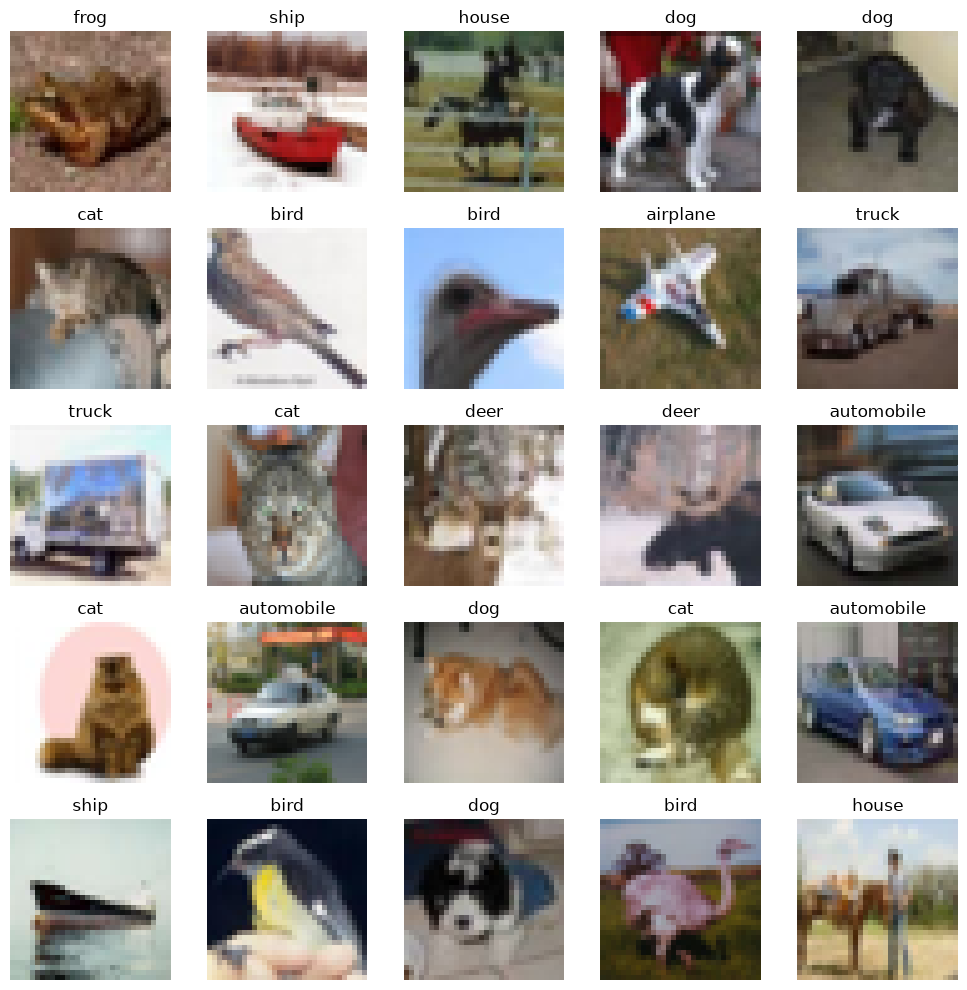

In [2]:
# Display 25 training images
fig, ax = plt.subplots(5, 5, figsize=(10, 10))

for i, ax in enumerate(ax.flat):
    image, label = train_set[i]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_name[label])
    ax.axis("off")


plt.tight_layout()
plt.show()

In [3]:
# Print batch shape
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])


In [4]:
# Count images in each class 
class_counts = np.zeros(10)

for _, label in train_full:
    class_counts[label] += 1

for i in range(10):
    print(class_name[i], ":", int(class_counts[i]))

airplane : 5000
automobile : 5000
bird : 5000
cat : 5000
deer : 5000
dog : 5000
frog : 5000
house : 5000
ship : 5000
truck : 5000


# **Part A — Convolution by hand, before any library**
## **TASK 01 — Compute one convolution on paper**

In [5]:
import torch
import torch.nn.functional as F

image = torch.tensor([
    [10, 10, 10, 90, 90],
    [10, 10, 10, 90, 90],
    [10, 10, 10, 90, 90],
    [10, 10, 10, 90, 90],
    [10, 10, 10, 90, 90]
], dtype=torch.float32)

filter_kernel = torch.tensor([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
], dtype=torch.float32)



# manual convolution
output = torch.zeros(3, 3)

for i in range(3):
    for j in range(3):
        region = image[i:i+3, j:j+3]
        output[i, j] = torch.sum(region * filter_kernel)

print("Manual Output:")
print(output)


# Verify using pytorch
image_tensor = image.reshape(1, 1, 5, 5)
filter_tensor = filter_kernel.reshape(1, 1, 3, 3)

torch_output = F.conv2d(image_tensor, filter_tensor)

print("\nPyTorch Output:")
print(torch_output[0, 0])

print("\nBoth Output Matches:", torch.equal(output, torch_output[0, 0]))

Manual Output:
tensor([[   0., -240., -240.],
        [   0., -240., -240.],
        [   0., -240., -240.]])

PyTorch Output:
tensor([[   0., -240., -240.],
        [   0., -240., -240.],
        [   0., -240., -240.]])

Both Output Matches: True


In [6]:
# Rotate filter by 90 degree
rotated_filter = torch.rot90(filter_kernel, 1, [0, 1])
rotated_output = F.conv2d(image_tensor, rotated_filter.reshape(1, 1, 3, 3))


print(rotated_output[0, 0])

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [7]:
# Uniform image experiment
uniform_image = torch.full((1, 1, 5, 5,), 50.0)
uniform_output = F.conv2d(uniform_image, filter_tensor)


print("Uniform Image Output:")
print(uniform_output)

Uniform Image Output:
tensor([[[[0., 0., 0.],
          [0., 0., 0.],
          [0., 0., 0.]]]])


**Observation :-** 
- Uniform images produce zero because there is no intensity difference or edge to detect.

## **TASK 02 — Derive the output size rule yourself**

Formula:- Output = [Input+ 2P - K / S] + 1

Where :-
- Input = input image size
- P = Padding
- K = Kernal Size
- S = Stride

In [8]:
def calculate_output(input_size, kernel, padding, stride):
    output = (
        (input_size + 2 * padding - kernel) // stride
    ) + 1
    
    return output

for kernel in [3, 5, 7]:
    for stride in [1, 2]:
        for padding in [0, 1, 2]:

            output = calculate_output(32, kernel, padding, stride)

            print(
                f"Kernel = {kernel} | ",
                f"Padding = {padding} | ",
                f"Stride = {stride} | ",
                f"Output = {output}"
            )

Kernel = 3 |  Padding = 0 |  Stride = 1 |  Output = 30
Kernel = 3 |  Padding = 1 |  Stride = 1 |  Output = 32
Kernel = 3 |  Padding = 2 |  Stride = 1 |  Output = 34
Kernel = 3 |  Padding = 0 |  Stride = 2 |  Output = 15
Kernel = 3 |  Padding = 1 |  Stride = 2 |  Output = 16
Kernel = 3 |  Padding = 2 |  Stride = 2 |  Output = 17
Kernel = 5 |  Padding = 0 |  Stride = 1 |  Output = 28
Kernel = 5 |  Padding = 1 |  Stride = 1 |  Output = 30
Kernel = 5 |  Padding = 2 |  Stride = 1 |  Output = 32
Kernel = 5 |  Padding = 0 |  Stride = 2 |  Output = 14
Kernel = 5 |  Padding = 1 |  Stride = 2 |  Output = 15
Kernel = 5 |  Padding = 2 |  Stride = 2 |  Output = 16
Kernel = 7 |  Padding = 0 |  Stride = 1 |  Output = 26
Kernel = 7 |  Padding = 1 |  Stride = 1 |  Output = 28
Kernel = 7 |  Padding = 2 |  Stride = 1 |  Output = 30
Kernel = 7 |  Padding = 0 |  Stride = 2 |  Output = 13
Kernel = 7 |  Padding = 1 |  Stride = 2 |  Output = 14
Kernel = 7 |  Padding = 2 |  Stride = 2 |  Output = 15


In [9]:
# Verify using PyTorch
for kernel in [3, 5, 7]:
    for padding in [0, 1, 2]:

        conv = nn.Conv2d(3, 16, kernel_size=kernel, padding=padding)
        sample = torch.randn(1, 3, 32, 32)

        result = conv(sample)

        print(
            f"Kernel = {kernel}, Padding = {padding},",
            f"Output Shape = {result.shape}"
        )

Kernel = 3, Padding = 0, Output Shape = torch.Size([1, 16, 30, 30])
Kernel = 3, Padding = 1, Output Shape = torch.Size([1, 16, 32, 32])
Kernel = 3, Padding = 2, Output Shape = torch.Size([1, 16, 34, 34])
Kernel = 5, Padding = 0, Output Shape = torch.Size([1, 16, 28, 28])
Kernel = 5, Padding = 1, Output Shape = torch.Size([1, 16, 30, 30])
Kernel = 5, Padding = 2, Output Shape = torch.Size([1, 16, 32, 32])
Kernel = 7, Padding = 0, Output Shape = torch.Size([1, 16, 26, 26])
Kernel = 7, Padding = 1, Output Shape = torch.Size([1, 16, 28, 28])
Kernel = 7, Padding = 2, Output Shape = torch.Size([1, 16, 30, 30])


In [10]:
# Five consecutive 3 x 3 convolutions without padding
size = 32

for i in range(5):
    size = size - 2
    print(f"After convolution {i+1}: {size} x {size}")

After convolution 1: 30 x 30
After convolution 2: 28 x 28
After convolution 3: 26 x 26
After convolution 4: 24 x 24
After convolution 5: 22 x 22


## **TASK 03 — Count the parameters, both ways**

In [11]:
# Dense Layer
dense_weight = (3 * 32 * 32) * (16 * 32 * 32)
dense_bias = 16 * 32 * 32

dense_total = dense_weight + dense_bias


print("Dense Weights:", dense_weight)
print("Dense Bias:", dense_bias)
print("Dense Total:", dense_total)

Dense Weights: 50331648
Dense Bias: 16384
Dense Total: 50348032


In [12]:
# Convolutional Layer
conv_weight = 16 * 3 * 3 * 3
conv_bias = 16

conv_total = conv_weight + conv_bias

print("CNN Weights:", conv_weight)
print("CNN Bias:", conv_bias)
print("CNN Total:", conv_total)

CNN Weights: 432
CNN Bias: 16
CNN Total: 448


In [13]:
# Compare Both
ratio = dense_total / conv_total

print("Dense Parameters:", dense_total)
print("CNN Parameters:", conv_total)

print("Parameter Ratio:", ratio)

Dense Parameters: 50348032
CNN Parameters: 448
Parameter Ratio: 112384.0


In [14]:
# Verify with PyTorch
dense_layer = nn.Linear(
    3 * 32 * 32,
    16 * 32 * 32
)

conv_layer = nn.Conv2d(
    3, 16, kernel_size=3
)


print("Dense PyTorch Parameters:",
     sum(p.numel() for p in dense_layer.parameters()))

print("CNN PyTorch Parameters:",
     sum(p.numel() for p in conv_layer.parameters()))

Dense PyTorch Parameters: 50348032
CNN PyTorch Parameters: 448


In [15]:
# Compare for 64 x 64 images
dense_64 = (3 * 64 * 64) * (16 * 64 * 64) + (16 * 64 * 64)
conv_64 = (16 * 3 * 3 * 3) + 16

print("Dense 64x64:", dense_64)
print("CNN 64x64:", conv_64)

print("Dense Growth:", dense_64 / dense_total)
print("CNN Growth:", conv_64 / conv_total)

Dense 64x64: 805371904
CNN 64x64: 448
Dense Growth: 15.99609502115197
CNN Growth: 1.0


# **Part B — Build and train**
## **TASK 04 — The dense baseline, first**

In [16]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

def evaluate(model, loader):
    model.eval()

    correct = 0
    total = 0
    total_loss = 0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()

            total += labels.size(0)


    accuracy = correct / total
    average_loss = total_loss / total

    return average_loss, accuracy


def train_model(model, train_loader, val_loader, epochs=10, learning_rate=0.001):

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.0001
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    start_time = time.time()

    for epoch in range(epochs):
        model.train()

        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        scheduler.step()

        print(
            f"Epoch {epoch+1}/{epochs} ",
            f"| Train Loss: {train_loss:.4f} ",
            f"| Train Acc: {train_acc:.4f} ",
            f"| Val Loss: {val_loss:.4f} ",
            f"| Val Acc: {val_acc:.4f}"
        )


    training_time = time.time() - start_time


    print("\nTraining Time:", round(training_time / 60, 2), "minutes")

    return model, history, training_time

In [17]:
def plot_loss(history, title):
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(history["train_loss"], label="Training Loss")
    ax.plot(history["val_loss"], label="Validation Loss")

    ax.set(xlabel="Epoch", ylabel="Loss", title=title)
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [18]:
# Dense Baseline
class DenseNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(), nn.Linear(3072, 512),
            nn.ReLU(), nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)

In [19]:
# Train the dense model
dense_model = DenseNet()

print("Dense Parameters:", count_parameters(dense_model))

dense_model, dense_history, dense_time = train_model(dense_model, train_loader, val_loader, epochs=10)

Dense Parameters: 1707274
Epoch 1/10  | Train Loss: 1.8732  | Train Acc: 0.3218  | Val Loss: 1.7888  | Val Acc: 0.3542
Epoch 2/10  | Train Loss: 1.6739  | Train Acc: 0.3974  | Val Loss: 1.6457  | Val Acc: 0.4168
Epoch 3/10  | Train Loss: 1.5803  | Train Acc: 0.4343  | Val Loss: 1.5939  | Val Acc: 0.4298
Epoch 4/10  | Train Loss: 1.5145  | Train Acc: 0.4603  | Val Loss: 1.5623  | Val Acc: 0.4460
Epoch 5/10  | Train Loss: 1.4684  | Train Acc: 0.4776  | Val Loss: 1.5325  | Val Acc: 0.4554
Epoch 6/10  | Train Loss: 1.4220  | Train Acc: 0.4919  | Val Loss: 1.4972  | Val Acc: 0.4710
Epoch 7/10  | Train Loss: 1.3737  | Train Acc: 0.5113  | Val Loss: 1.4647  | Val Acc: 0.4854
Epoch 8/10  | Train Loss: 1.3416  | Train Acc: 0.5230  | Val Loss: 1.4560  | Val Acc: 0.4846
Epoch 9/10  | Train Loss: 1.3144  | Train Acc: 0.5323  | Val Loss: 1.4526  | Val Acc: 0.4878
Epoch 10/10  | Train Loss: 1.2987  | Train Acc: 0.5396  | Val Loss: 1.4451  | Val Acc: 0.4864

Training Time: 0.9 minutes


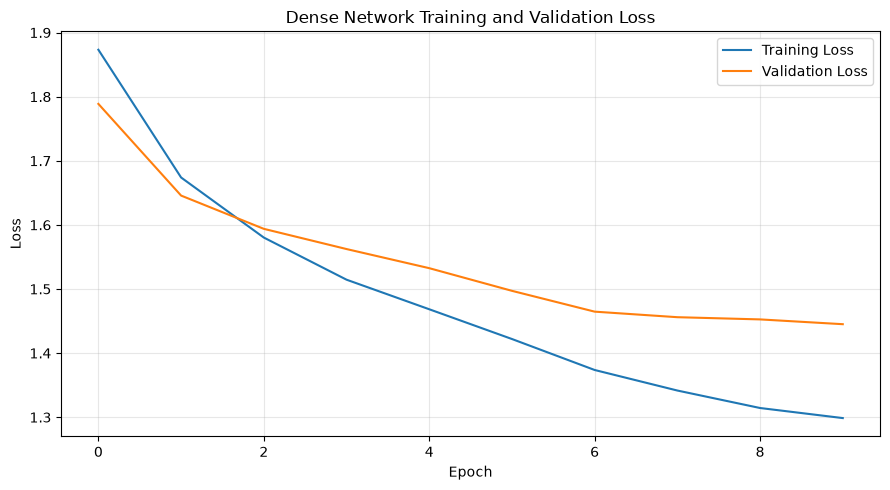

In [20]:
# Plot training and validation loss:
plot_loss(dense_history, "Dense Network Training and Validation Loss")

In [21]:
# Validation Accuracy
dense_loss, dense_accuracy = evaluate(dense_model, val_loader)


print("Dense Validation Accuracy:", dense_accuracy)

Dense Validation Accuracy: 0.4864


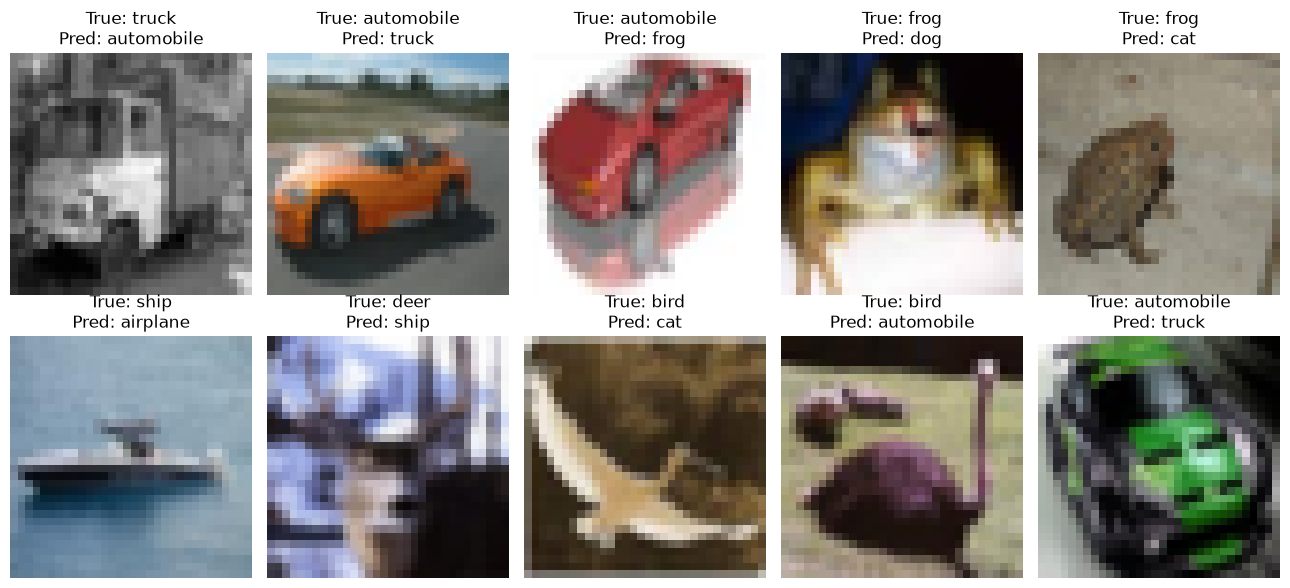

In [22]:
# Display 10 incorrect predictions
def show_wrong_images(model, loader, number=10):
    model.eval()

    wrong_images = []
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            predictions = outputs.argmax(dim=1).cpu()
            wrong = predictions != labels

            for index in torch.where(wrong)[0]:
                wrong_images.append(images[index])
                true_labels.append(labels[index].item())
                predicted_labels.append(predictions[index].item())

                if len(wrong_images) == number:
                    break

            if len(wrong_images) == number:
                break

    fig, ax = plt.subplots(2, 5, figsize=(13, 6))

    for i, ax in enumerate(ax.flat):
        if i >= len(wrong_images):
            ax.axis("off")
            continue

        ax.imshow(wrong_images[i].permute(1, 2, 0))
        ax.set_title(
            f"True: {class_name[true_labels[i]]}\n"
            f"Pred: {class_name[predicted_labels[i]]}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()



show_wrong_images(dense_model, val_loader, 10)

## **TASK 05 — Your first CNN**

In [23]:
class CNN(nn.Module):

    def __init__(self, pooling="max", use_pool=True, first_kernel=3,
                batch_norm=False, extra_block=False):

        super().__init__()

        Pool = nn.MaxPool2d if pooling == "max" else nn.AvgPool2d
        layers = []

        def block(in_channels, out_channels, kernel=3):
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=kernel, padding=kernel // 2))

            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.append(nn.ReLU())

            if use_pool:
                layers.append(Pool(2))

        block(3, 64, first_kernel)
        block(64, 128)

        if extra_block:
            block(128, 256)


        self.features = nn.Sequential(*layers)

        with torch.no_grad():
            dummy = torch.zeros(1, 3, 32, 32)
            output = self.features(dummy)
            flatten_size = output.flatten(1).shape[1]

        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(flatten_size, 256),
                                       nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 10))


    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)

        return x

In [24]:
# Check output shape after every layer
cnn_model = CNN().to(device)
sample = torch.randn(1, 3, 32, 32).to(device)

print("Input:", sample.shape)

for layer in cnn_model.features:
    sample = layer(sample)
    print(
        layer.__class__.__name__,
        sample.shape
    )


print("Flattened Output:", sample.flatten(1).shape)
print("Final Output:", cnn_model.classifier(sample).shape)

Input: torch.Size([1, 3, 32, 32])
Conv2d torch.Size([1, 64, 32, 32])
ReLU torch.Size([1, 64, 32, 32])
MaxPool2d torch.Size([1, 64, 16, 16])
Conv2d torch.Size([1, 128, 16, 16])
ReLU torch.Size([1, 128, 16, 16])
MaxPool2d torch.Size([1, 128, 8, 8])
Flattened Output: torch.Size([1, 8192])
Final Output: torch.Size([1, 10])


In [25]:
# Train CNN
cnn_model = CNN()

print("CNN parameters:", count_parameters(cnn_model))

cnn_model, cnn_history, cnn_time = train_model(cnn_model, train_loader,
                                              val_loader, epochs=30)

CNN parameters: 2175626
Epoch 1/30  | Train Loss: 1.6360  | Train Acc: 0.4036  | Val Loss: 1.3579  | Val Acc: 0.5196
Epoch 2/30  | Train Loss: 1.2713  | Train Acc: 0.5440  | Val Loss: 1.1783  | Val Acc: 0.5894
Epoch 3/30  | Train Loss: 1.1133  | Train Acc: 0.6041  | Val Loss: 1.0377  | Val Acc: 0.6372
Epoch 4/30  | Train Loss: 0.9982  | Train Acc: 0.6443  | Val Loss: 0.9691  | Val Acc: 0.6624
Epoch 5/30  | Train Loss: 0.9181  | Train Acc: 0.6747  | Val Loss: 0.9780  | Val Acc: 0.6518
Epoch 6/30  | Train Loss: 0.8535  | Train Acc: 0.6962  | Val Loss: 0.8967  | Val Acc: 0.6832
Epoch 7/30  | Train Loss: 0.8009  | Train Acc: 0.7168  | Val Loss: 0.8732  | Val Acc: 0.6998
Epoch 8/30  | Train Loss: 0.7483  | Train Acc: 0.7350  | Val Loss: 0.8498  | Val Acc: 0.7048
Epoch 9/30  | Train Loss: 0.7049  | Train Acc: 0.7496  | Val Loss: 0.8613  | Val Acc: 0.7050
Epoch 10/30  | Train Loss: 0.6578  | Train Acc: 0.7659  | Val Loss: 0.8522  | Val Acc: 0.7046
Epoch 11/30  | Train Loss: 0.6201  | Train Ac

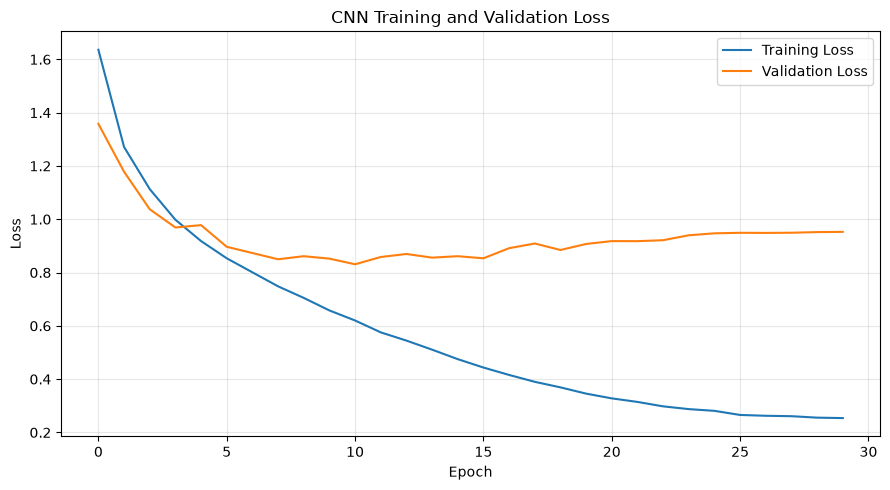

In [26]:
# Plot Loss:
plot_loss(cnn_history, "CNN Training and Validation Loss")

In [27]:
# Compare dense and CNN parameters
print("Dense Parameters:", count_parameters(dense_model))
print("CNN Parameters:", count_parameters(cnn_model))

print("Dense Training Time:", dense_time / 60, "minutes")
print("CNN Training Time:", cnn_time / 60, "minutes")

Dense Parameters: 1707274
CNN Parameters: 2175626
Dense Training Time: 0.9017558773358663 minutes
CNN Training Time: 22.640207119782765 minutes


In [28]:
# Remove pooling
no_pool_model = CNN(use_pool=False)

no_pool_model, no_pool_history, no_pool_time = train_model(no_pool_model, train_loader, val_loader, epochs=8)

no_pool_loss, no_pool_accuracy = evaluate(no_pool_model, val_loader)

print("No Pooling Parameters:", count_parameters(no_pool_model))
print("No Pooling Time:", no_pool_time / 60)
print("No Pooling Accuracy:", no_pool_accuracy)

Epoch 1/8  | Train Loss: 1.5897  | Train Acc: 0.4284  | Val Loss: 1.3242  | Val Acc: 0.5304
Epoch 2/8  | Train Loss: 1.2267  | Train Acc: 0.5588  | Val Loss: 1.1771  | Val Acc: 0.5876
Epoch 3/8  | Train Loss: 1.0302  | Train Acc: 0.6312  | Val Loss: 1.0819  | Val Acc: 0.6232
Epoch 4/8  | Train Loss: 0.8570  | Train Acc: 0.6937  | Val Loss: 1.0483  | Val Acc: 0.6340
Epoch 5/8  | Train Loss: 0.7123  | Train Acc: 0.7471  | Val Loss: 1.0432  | Val Acc: 0.6524
Epoch 6/8  | Train Loss: 0.5785  | Train Acc: 0.7970  | Val Loss: 1.0518  | Val Acc: 0.6520
Epoch 7/8  | Train Loss: 0.4760  | Train Acc: 0.8364  | Val Loss: 1.0630  | Val Acc: 0.6630
Epoch 8/8  | Train Loss: 0.4213  | Train Acc: 0.8573  | Val Loss: 1.0778  | Val Acc: 0.6626

Training Time: 25.85 minutes
No Pooling Parameters: 33632906
No Pooling Time: 25.84893771012624
No Pooling Accuracy: 0.6626


In [29]:
# Average Pooling
avg_pooling_model = CNN(pooling="average")

avg_pooling_model, avg_history, avg_time = train_model(avg_pooling_model, train_loader, val_loader, epochs=8)

avg_loss, avg_accuracy = evaluate(avg_pooling_model, val_loader)


print("Average Pooling Parameters:", count_parameters(avg_pooling_model))
print("Average Pooling Time:", avg_time / 60)
print("Average Pooling Accuracy:", avg_accuracy)

Epoch 1/8  | Train Loss: 1.6193  | Train Acc: 0.4120  | Val Loss: 1.3780  | Val Acc: 0.5112
Epoch 2/8  | Train Loss: 1.3051  | Train Acc: 0.5304  | Val Loss: 1.2292  | Val Acc: 0.5630
Epoch 3/8  | Train Loss: 1.1613  | Train Acc: 0.5869  | Val Loss: 1.1589  | Val Acc: 0.5876
Epoch 4/8  | Train Loss: 1.0544  | Train Acc: 0.6258  | Val Loss: 1.0453  | Val Acc: 0.6350
Epoch 5/8  | Train Loss: 0.9669  | Train Acc: 0.6584  | Val Loss: 1.0101  | Val Acc: 0.6446
Epoch 6/8  | Train Loss: 0.9047  | Train Acc: 0.6822  | Val Loss: 0.9978  | Val Acc: 0.6492
Epoch 7/8  | Train Loss: 0.8553  | Train Acc: 0.6975  | Val Loss: 0.9634  | Val Acc: 0.6580
Epoch 8/8  | Train Loss: 0.8263  | Train Acc: 0.7070  | Val Loss: 0.9496  | Val Acc: 0.6702

Training Time: 6.04 minutes
Average Pooling Parameters: 2175626
Average Pooling Time: 6.037751440207163
Average Pooling Accuracy: 0.6702


# **Part C — Prove it is using the grid**
## **TASK 06 — The pixel shuffle test**

In [30]:
pixel_permutation = torch.randperm(32 * 32,
                                  generator=torch.Generator().manual_seed(0))


def shuffle_pixels(image):
    # image shape: [3, 32, 32]

    image = image.reshape(3, 1024)
    image = image[:, pixel_permutation]
    image = image.reshape(3, 32, 32)

    return image

In [31]:
# create shuffled datasets:
class ShuffledDataset(Dataset):

    def __init__(self, original_dataset, mode="full"):
        self.original_dataset = original_dataset
        self.mode = mode


    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, index):
        image, label = self.original_dataset[index]

        if self.mode == "full":
            image = shuffle_pixels(image)
        return image, label


shuffled_train_set = ShuffledDataset(train_set)
shuffled_val_set = ShuffledDataset(val_set)

shuffled_train_loader = DataLoader(shuffled_train_set, batch_size=128, shuffle=True)
shuffled_val_loader = DataLoader(shuffled_val_set, batch_size=128, shuffle=False)

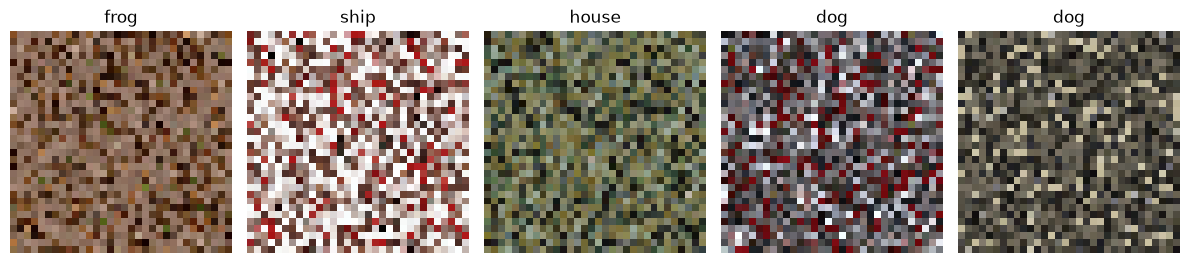

In [32]:
# Display shuffled images
fig, ax = plt.subplots(1, 5, figsize=(12, 4))

for i, ax in enumerate(ax):
    image, label = shuffled_train_set[i]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_name[label])
    ax.axis("off")


plt.tight_layout()
plt.show()

In [33]:
# Train dense network on shuffled data
dense_shuffled = DenseNet()

dense_shuffled, dense_shuffle_history, _ = train_model(
    dense_shuffled, shuffled_train_loader, shuffled_val_loader,
    epochs=8
)

dense_shuffled_accuracy = evaluate(dense_shuffled, shuffled_val_loader)[1]

print("Dense Shuffled Accuracy:", dense_shuffled_accuracy)

Epoch 1/8  | Train Loss: 1.8613  | Train Acc: 0.3261  | Val Loss: 1.7750  | Val Acc: 0.3550
Epoch 2/8  | Train Loss: 1.6679  | Train Acc: 0.4015  | Val Loss: 1.6857  | Val Acc: 0.4020
Epoch 3/8  | Train Loss: 1.5736  | Train Acc: 0.4407  | Val Loss: 1.6068  | Val Acc: 0.4306
Epoch 4/8  | Train Loss: 1.4992  | Train Acc: 0.4669  | Val Loss: 1.5422  | Val Acc: 0.4522
Epoch 5/8  | Train Loss: 1.4424  | Train Acc: 0.4880  | Val Loss: 1.5277  | Val Acc: 0.4664
Epoch 6/8  | Train Loss: 1.3953  | Train Acc: 0.5017  | Val Loss: 1.4904  | Val Acc: 0.4738
Epoch 7/8  | Train Loss: 1.3546  | Train Acc: 0.5188  | Val Loss: 1.4775  | Val Acc: 0.4786
Epoch 8/8  | Train Loss: 1.3307  | Train Acc: 0.5268  | Val Loss: 1.4628  | Val Acc: 0.4852

Training Time: 0.81 minutes
Dense Shuffled Accuracy: 0.4852


In [34]:
# Train CNN on Shuffled data
cnn_shuffled = CNN()

cnn_shuffled, cnn_shuffled_history, _ = train_model(
    cnn_shuffled, shuffled_train_loader, shuffled_val_loader, epochs=8
)

cnn_shuffled_accuracy = evaluate(cnn_shuffled, shuffled_val_loader)[1]


print("CNN Shuffled Accuracy:", cnn_shuffled_accuracy)

Epoch 1/8  | Train Loss: 1.9621  | Train Acc: 0.2676  | Val Loss: 1.7796  | Val Acc: 0.3550
Epoch 2/8  | Train Loss: 1.7040  | Train Acc: 0.3755  | Val Loss: 1.6275  | Val Acc: 0.4112
Epoch 3/8  | Train Loss: 1.5765  | Train Acc: 0.4305  | Val Loss: 1.5357  | Val Acc: 0.4460
Epoch 4/8  | Train Loss: 1.4942  | Train Acc: 0.4597  | Val Loss: 1.4988  | Val Acc: 0.4624
Epoch 5/8  | Train Loss: 1.4290  | Train Acc: 0.4870  | Val Loss: 1.4517  | Val Acc: 0.4874
Epoch 6/8  | Train Loss: 1.3772  | Train Acc: 0.5046  | Val Loss: 1.4371  | Val Acc: 0.4906
Epoch 7/8  | Train Loss: 1.3392  | Train Acc: 0.5193  | Val Loss: 1.4160  | Val Acc: 0.4972
Epoch 8/8  | Train Loss: 1.3177  | Train Acc: 0.5284  | Val Loss: 1.4036  | Val Acc: 0.5020

Training Time: 6.68 minutes
CNN Shuffled Accuracy: 0.502


In [35]:
# Compare all four results
dense_normal_accuracy = evaluate(dense_model, val_loader)[1]
cnn_noraml_accuracy = evaluate(cnn_model, val_loader)[1]

print("Pixel Shuffle Comparison")
print("-" * 25)
print("Dense Normal:", dense_normal_accuracy)
print("Dense Shuffled:", dense_shuffled_accuracy)
print("CNN Normal:", cnn_noraml_accuracy)
print("CNN Shuffled:", cnn_shuffled_accuracy)

Pixel Shuffle Comparison
-------------------------
Dense Normal: 0.4864
Dense Shuffled: 0.4852
CNN Normal: 0.7304
CNN Shuffled: 0.502


In [36]:
# Shuffle within each 4x4 block
block_permutation = torch.randperm(16, 
                                  generator=torch.Generator().manual_seed(1))


def shuffle_blocks(image):
    image = image.reshape(3, 8, 4, 8, 4)
    image = image.permute(0, 1, 2, 3, 4)
    image = image.reshape(3, 8, 8, 16)
    image = image[:, :, :, block_permutation]
    image = image.reshape(3, 8, 8, 4, 4)
    image = image.permute(0, 1, 3, 2, 4)
    return image.reshape(3, 32, 32)


class BlockShuffleDataset(Dataset):
    def __init__(self, original_dataset):
        self.original_dataset = original_dataset

    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, index):
        image, label = self.original_dataset[index]
        return shuffle_blocks(image), label


block_train_set = BlockShuffleDataset(train_set)
block_val_set = BlockShuffleDataset(val_set)

block_train_loader = DataLoader(block_train_set, batch_size=128, shuffle=True)
block_val_loader = DataLoader(block_val_set, batch_size=128, shuffle=False)

block_cnn = CNN()
block_cnn, _, _ = train_model(block_cnn, block_train_loader, block_val_loader, epochs=8)


print("CNN Accuracy after block shuffle:", evaluate(block_cnn, block_val_loader)[1])

Epoch 1/8  | Train Loss: 1.7288  | Train Acc: 0.3721  | Val Loss: 1.5298  | Val Acc: 0.4430
Epoch 2/8  | Train Loss: 1.4615  | Train Acc: 0.4729  | Val Loss: 1.3761  | Val Acc: 0.5088
Epoch 3/8  | Train Loss: 1.3475  | Train Acc: 0.5140  | Val Loss: 1.3288  | Val Acc: 0.5236
Epoch 4/8  | Train Loss: 1.2680  | Train Acc: 0.5435  | Val Loss: 1.2866  | Val Acc: 0.5436
Epoch 5/8  | Train Loss: 1.2029  | Train Acc: 0.5669  | Val Loss: 1.2231  | Val Acc: 0.5686
Epoch 6/8  | Train Loss: 1.1433  | Train Acc: 0.5921  | Val Loss: 1.1925  | Val Acc: 0.5784
Epoch 7/8  | Train Loss: 1.1021  | Train Acc: 0.6055  | Val Loss: 1.1789  | Val Acc: 0.5822
Epoch 8/8  | Train Loss: 1.0776  | Train Acc: 0.6158  | Val Loss: 1.1648  | Val Acc: 0.5876

Training Time: 6.57 minutes
CNN Accuracy after block shuffle: 0.5876


## **TASK 07 — The translation test**

In [37]:
def shift_image(images, pixels):
    return torch.roll(
        images, shifts=(pixels, pixels), dims=(2, 3)
    )

In [38]:
# Evaluate shifted images
def evaluate_shift(model, loader, pixels):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = shift_image(images, pixels)

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return correct / total

In [39]:
# Run Translation Experiment
shift_values = [0, 1, 2, 4, 8]

dense_shift_results = []
cnn_shift_results = []

for pixels in shift_values:
    dense_acc = evaluate_shift(dense_model, val_loader, pixels)
    cnn_acc = evaluate_shift(cnn_model, val_loader, pixels)

    dense_shift_results.append(dense_acc)
    cnn_shift_results.append(cnn_acc)


    print(f"Shift {pixels}: "
         f"Dense = {dense_acc:.4f}, "
         f"CNN = {cnn_acc:.4f}")

Shift 0: Dense = 0.4864, CNN = 0.7304
Shift 1: Dense = 0.4560, CNN = 0.6976
Shift 2: Dense = 0.4008, CNN = 0.6360
Shift 4: Dense = 0.2944, CNN = 0.4896
Shift 8: Dense = 0.2048, CNN = 0.2594


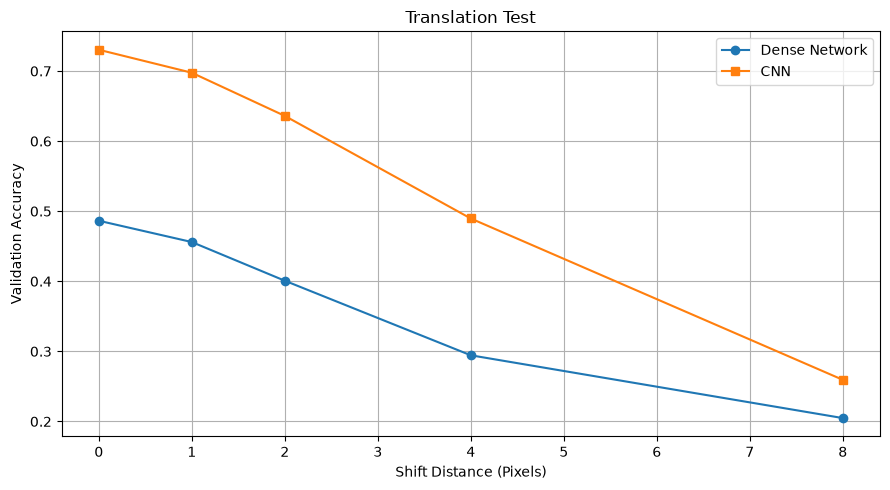

In [40]:
# Plot accuracy against shift distance
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(shift_values, dense_shift_results, marker="o", label="Dense Network")
ax.plot(shift_values, cnn_shift_results, marker="s", label="CNN")

ax.set(xlabel="Shift Distance (Pixels)", ylabel="Validation Accuracy", title="Translation Test")
ax.legend()
ax.grid(0.3)

plt.tight_layout()
plt.show()

In [41]:
# Find the 10 percentage point drop
def find_drop_distance(results):
    starting_accuracy = results[0]

    for shift, accuracy in zip(shift_values, results):
        if accuracy <= starting_accuracy - 0.10:
            return shift

    return "Not reached"



print("Dense 10-point drop:", find_drop_distance(dense_shift_results))
print("CNN 10-point drop:", find_drop_distance(cnn_shift_results))

Dense 10-point drop: 4
CNN 10-point drop: 4


# **Part D — Look inside**
## **TASK 08 — Visualise the first-layer filters**

In [42]:
def get_conv_layers(model):
    conv_layers = []

    for layer in model.modules():
        if isinstance(layer, nn.Conv2d):
            conv_layers.append(layer)

    return conv_layers


conv_layers = get_conv_layers(cnn_model)

first_conv = conv_layers[0]
weights = first_conv.weight.detach().cpu()

print("First layer filter shape:", weights.shape)

First layer filter shape: torch.Size([64, 3, 3, 3])


- 64 = Number of filters
- 3 = Input colour channels
- 3 = Filter height
- 3 = Filter width

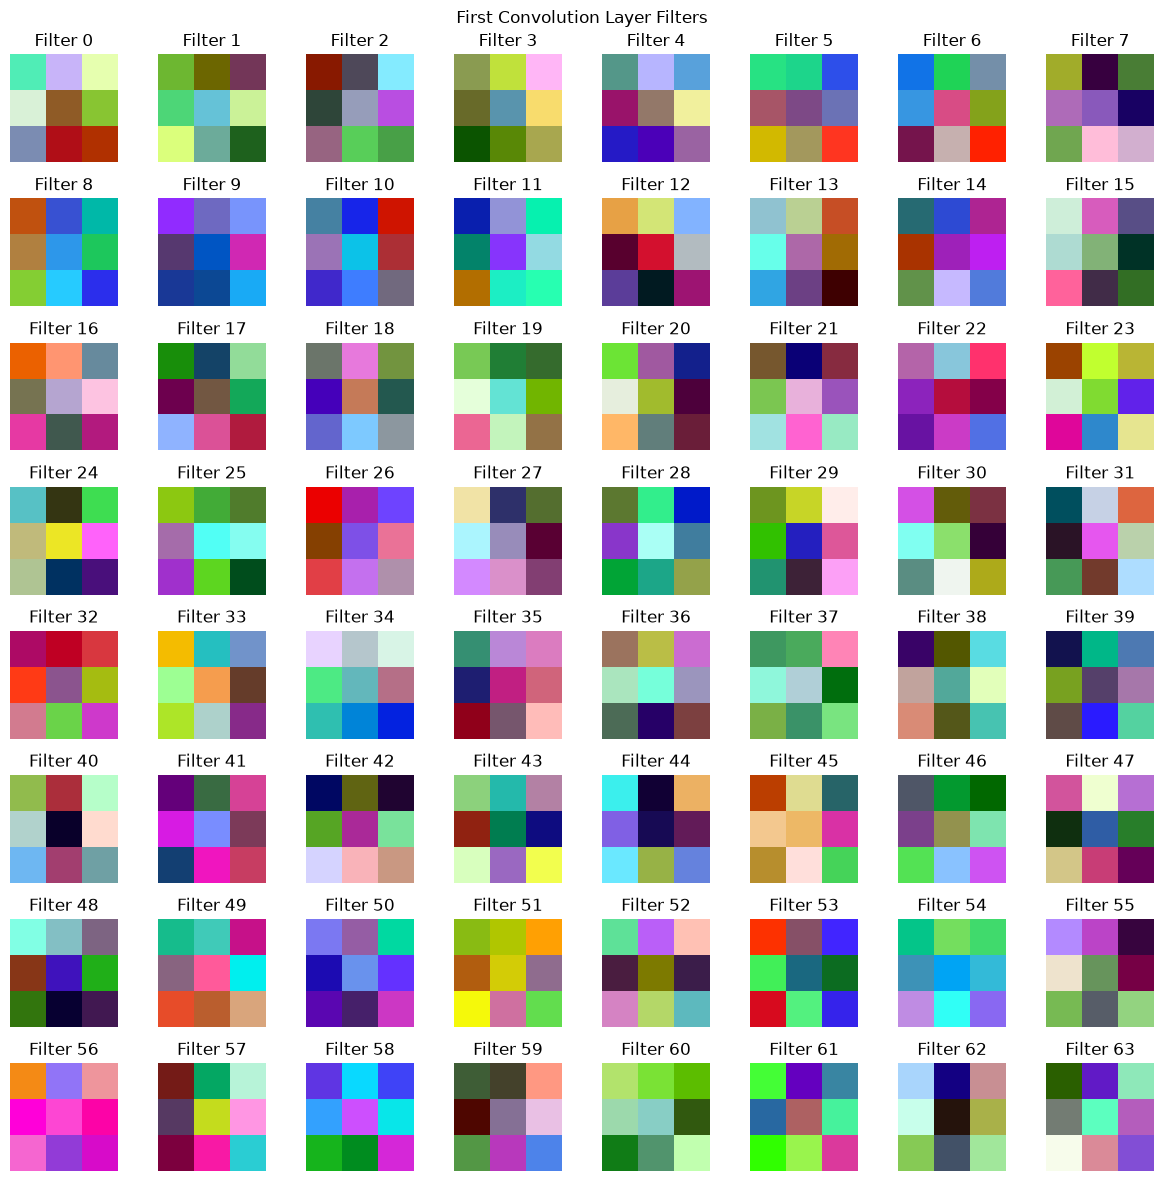

In [43]:
# Display all first-layer filters
def visualize_filters(model):
    conv_layers = get_conv_layers(model)

    weights = conv_layers[0].weight.detach().cpu()
    number_of_filters = weights.shape[0]

    fig, ax = plt.subplots(8, 8, figsize=(12, 12))

    for i, ax in enumerate(ax.flat):
        if i >= number_of_filters:
            ax.axis("off")
            continue

        filt = weights[i].permute(1, 2, 0).numpy()

        minimum = filt.min()
        maximum = filt.max()

        filt = (filt - minimum) / (maximum - minimum + 1e-8)

        ax.imshow(filt)
        ax.set_title(f"Filter {i}")
        ax.axis("off")

    plt.suptitle("First Convolution Layer Filters")
    plt.tight_layout()
    plt.show()


visualize_filters(cnn_model)

In [47]:
def calculate_plane_scores(model):
    conv_layers = get_conv_layers(model)

    weights = conv_layers[0].weight.detach().cpu().numpy()
    scores = []

    for filt in weights:
        channels, height, width = filt.shape

        yy, xx = np.mgrid[0:height, 0:width]
        X = np.column_stack([
            xx.flatten(),
            yy.flatten(), 
            np.ones(height * width)
        ])

        total_variation = 0
        residual_variation = 0

        for channel in range(channels):
            values = filt[channel].flatten()

            coefficients, _, _, _ = np.linalg.lstsq(X, values, rcond=None)
            predicted = X @ coefficients

            total_variation += np.sum((values - values.mean()) ** 2)

            residual_variation += np.sum((values - predicted) ** 2)

        score = 1 - (residual_variation / (total_variation + 1e-8))

        scores.append(score)

    return np.array(scores)


plane_scores = calculate_plane_scores(cnn_model)

edge_count = np.sum(plane_scores > 0.7)
blob_or_other_count = len(plane_scores) - edge_count

print("Edge-Like filters:", edge_count)
print("Blob-Like or other filters:", blob_or_other_count)
print("Mean plane-fit score:", plane_scores.mean())

Edge-Like filters: 6
Blob-Like or other filters: 58
Mean plane-fit score: 0.37451988526118896


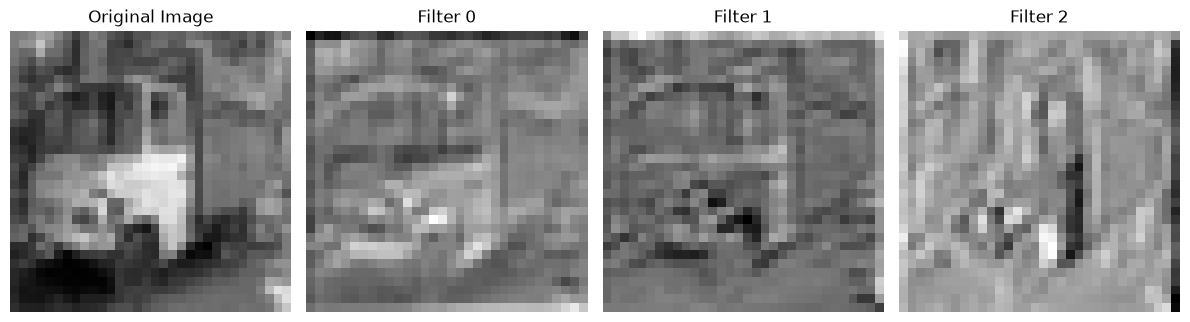

In [48]:
# Display three feature maps
def show_feature_maps(model, dataset):
    model.eval()

    conv_layers = get_conv_layers(model)

    first_conv = conv_layers[0]
    image, label = dataset[0]

    input_image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        feature_maps = first_conv(input_image)

    feature_maps = feature_maps.cpu()[0]


    fig, ax = plt.subplots(1, 4, figsize=(12, 4))

    ax[0].imshow(image.permute(1, 2, 0))
    ax[0].set_title("Original Image")
    ax[0].axis("off")

    for i in range(3):
        ax[i+1].imshow(feature_maps[i], cmap="gray")
        ax[i+1].set_title(f"Filter {i}")
        ax[i+1].axis("off")


    plt.tight_layout()
    plt.show()


show_feature_maps(cnn_model, val_set)

In [49]:
# Compare normal CNN and Shuffled CNN filters
normal_scores = calculate_plane_scores(cnn_model)
shuffled_scores = calculate_plane_scores(cnn_shuffled)

print("Normal CNN mean plane score:", normal_scores.mean())
print("Shuffled CNN mean plane score:", shuffled_scores.mean())
print("Normal edge-like filters:", np.sum(normal_scores > 0.7))
print("Shuffled edge-like filters:", np.sum(shuffled_scores > 0.7))

Normal CNN mean plane score: 0.37451988526118896
Shuffled CNN mean plane score: 0.27363576629253905
Normal edge-like filters: 6
Shuffled edge-like filters: 0


7x7 CNN Parameters: 2183306
Epoch 1/8  | Train Loss: 1.5779  | Train Acc: 0.4302  | Val Loss: 1.3299  | Val Acc: 0.5276
Epoch 2/8  | Train Loss: 1.2328  | Train Acc: 0.5618  | Val Loss: 1.1973  | Val Acc: 0.5762
Epoch 3/8  | Train Loss: 1.0661  | Train Acc: 0.6232  | Val Loss: 1.0782  | Val Acc: 0.6226
Epoch 4/8  | Train Loss: 0.9537  | Train Acc: 0.6656  | Val Loss: 0.9649  | Val Acc: 0.6658
Epoch 5/8  | Train Loss: 0.8563  | Train Acc: 0.7006  | Val Loss: 0.9312  | Val Acc: 0.6748
Epoch 6/8  | Train Loss: 0.7758  | Train Acc: 0.7274  | Val Loss: 0.8922  | Val Acc: 0.6898
Epoch 7/8  | Train Loss: 0.7151  | Train Acc: 0.7525  | Val Loss: 0.8805  | Val Acc: 0.6968
Epoch 8/8  | Train Loss: 0.6817  | Train Acc: 0.7611  | Val Loss: 0.8742  | Val Acc: 0.6982

Training Time: 6.94 minutes
7x7 CNN Validation Accuracy: 0.6982
7x7 CNN Training Time: 6.935804963111877


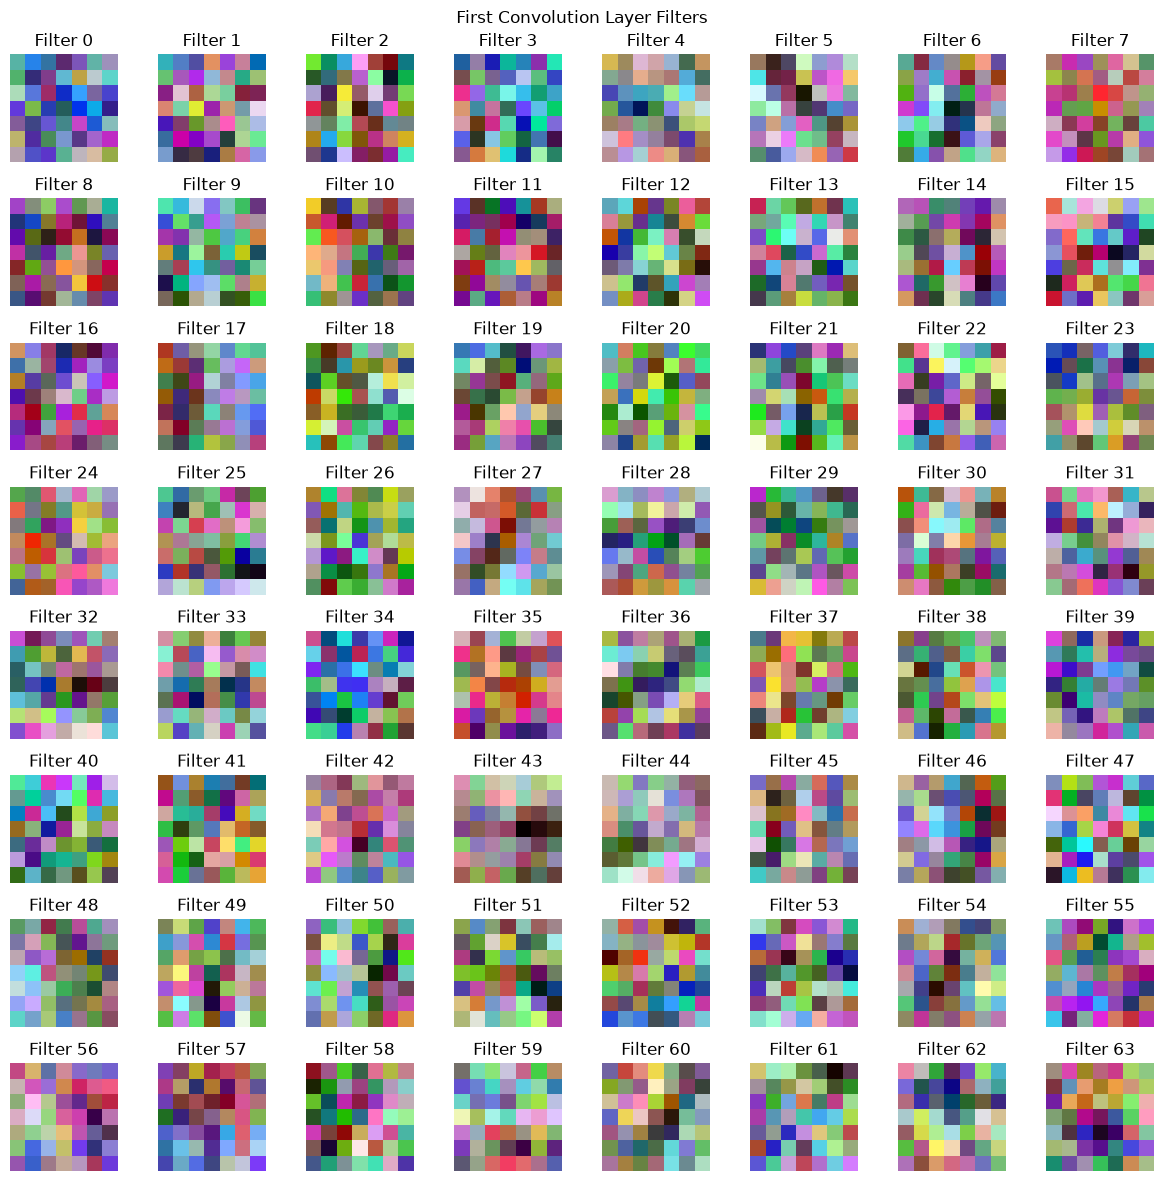

In [50]:
# Train a CNN with a 7x7 first convolution
cnn_7x7 = CNN(first_kernel=7)

print("7x7 CNN Parameters:", count_parameters(cnn_7x7))

cnn_7x7, history_7x7, time_7x7 = train_model(cnn_7x7, train_loader, val_loader, epochs=8)

print("7x7 CNN Validation Accuracy:", evaluate(cnn_7x7, val_loader)[1])
print("7x7 CNN Training Time:", time_7x7 / 60)

visualize_filters(cnn_7x7)

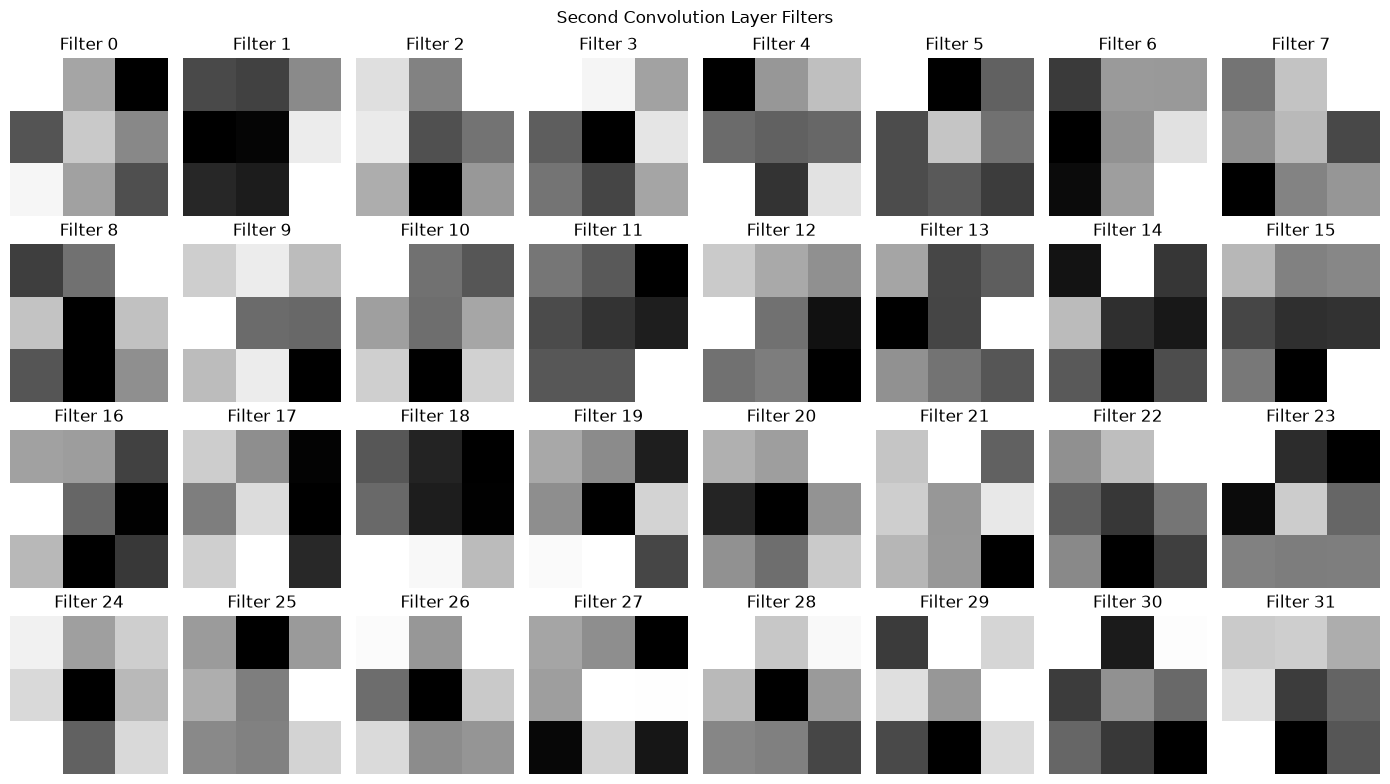

In [51]:
# Visualize second-layer filters
def visualize_second_layer(model):
    conv_layers = get_conv_layers(model)
    weights = conv_layers[1].weight.detach().cpu()

    fig, ax = plt.subplots(4, 8, figsize=(14, 8))

    for i, ax in enumerate(ax.flat):
        if i >= weights.shape[0]:
            ax.axis("off")
            continue

        # Average across input channels for display.
        filt = weights[i].mean(dim=0).numpy()

        ax.imshow(filt, cmap="gray")
        ax.set_title(f"Filter {i}")
        ax.axis("off")

    plt.suptitle("Second Convolution Layer Filters")
    plt.tight_layout()
    plt.show()


visualize_second_layer(cnn_model)

## **TASK 09 — Read the errors**

In [53]:
# Confusion matrix and error analysis
def get_predictions(model, loader):
    model.eval()

    all_predictions = []
    all_labels = []
    all_images = []

    with torch.no_grad():
        for images, labels in loader:

            outputs = model(images.to(device))
            predictions = outputs.argmax(dim=1).cpu()

            all_predictions.extend(predictions.numpy())
            all_labels.extend(labels.numpy())
            all_images.extend(images)

    return(
        np.array(all_labels),
        np.array(all_predictions),
        all_images
    )


true_labels, predicted_labels, all_images = get_predictions(cnn_model, val_loader)

In [54]:
# Create Confusion matrix
confusion_matrix = np.zeros((10, 10), dtype=int)

for true, predicted in zip(true_labels, predicted_labels):
    confusion_matrix[true, predicted] += 1

print(confusion_matrix)

[[376   9  18  10  11   2   8   9  20  19]
 [  7 424   2   7   3   4   3   0  10  48]
 [ 28   4 313  30  35  24  31  15   8   6]
 [ 14   5  26 271  28  92  36  16  10   6]
 [  7   3  45  31 361  20  26  32   3   4]
 [  6   4  29  93  18 307  18  21   6   5]
 [  5   4  19  30  15   6 415   1   3   4]
 [  4   3  22  21  38  27   0 381   2   8]
 [ 31  15   8   5   0   2   8   0 423   6]
 [ 14  31   6  11   2   6   5   4   7 381]]


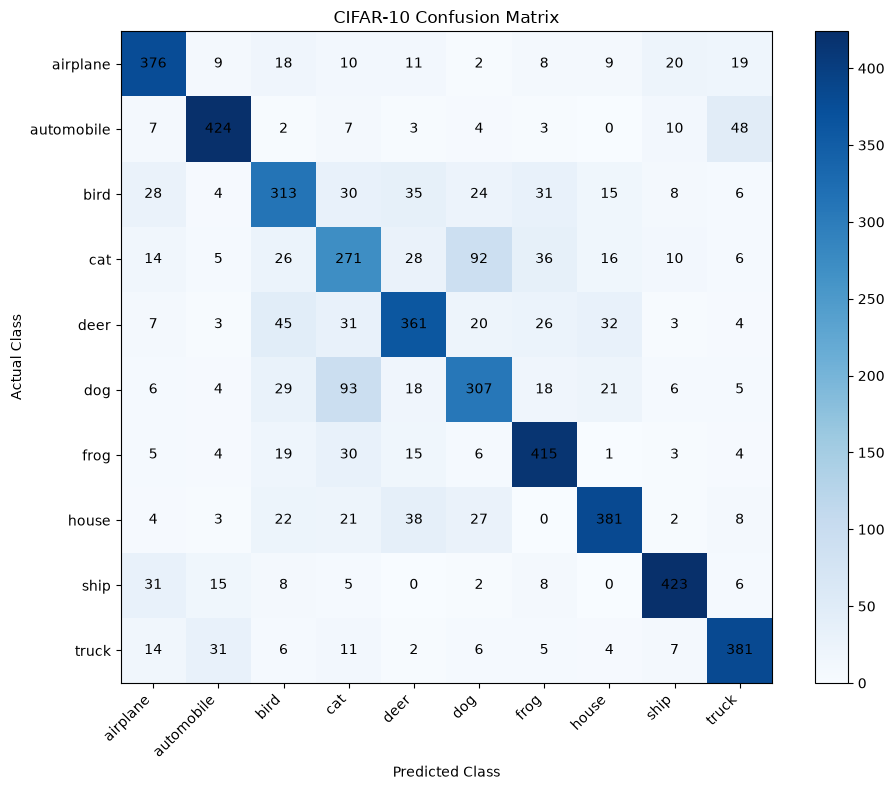

In [61]:
# Plot confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(confusion_matrix, cmap="Blues")
fig.colorbar(im, ax=ax)

ax.set_xticks(range(10))
ax.set_xticklabels(class_name, rotation=45, ha="right")

ax.set_yticks(range(10))
ax.set_yticklabels(class_name)

for i in range(10):
    for j in range(10):
        ax.text(
            j, i,
            str(confusion_matrix[i, j]),
            ha="center",
            va="center",
            color="black"
        )

ax.set(xlabel="Predicted Class", ylabel="Actual Class", title="CIFAR-10 Confusion Matrix")

plt.tight_layout()
plt.show()

In [60]:
# Find three worst confused pairs
pairs = []

for true_class in range(10):
    for predicted_class in range(10):
        if true_class != predicted_class:
            count = confusion_matrix[true_class, predicted_class]
            pairs.append((count, true_class, predicted_class))


pairs.sort(reverse=True)

print("Three worst confused pairs:\n")

for count, true_class, predicted_class in pairs[:3]:

    print(
        class_name[true_class], "predicted as",
        class_name[predicted_class], "Count:",
        count
    )

Three worst confused pairs:

dog predicted as cat Count: 93
cat predicted as dog Count: 92
automobile predicted as truck Count: 48


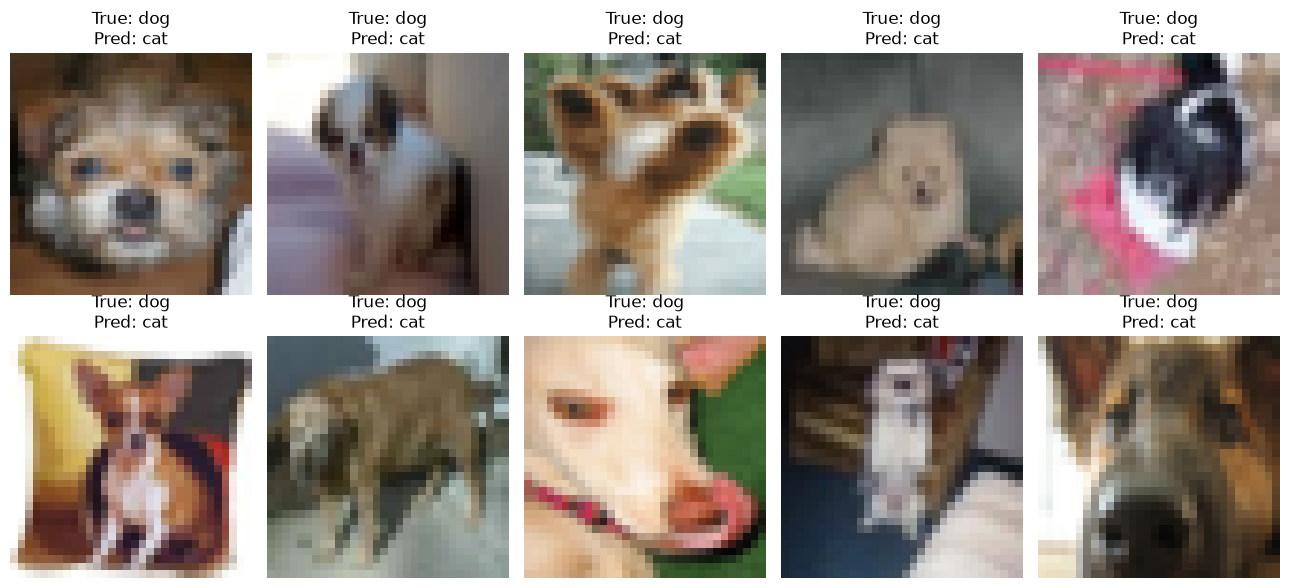

In [63]:
# Display misclassified images from the worst pair
worst_count, worst_true, worst_predicted = pairs[0]

indices = np.where(
    (true_labels == worst_true) &
    (predicted_labels == worst_predicted)
)[0][:10]

fig, ax = plt.subplots(2, 5, figsize=(13, 6))
for i, ax in enumerate(ax.flat):
    if i >= len(indices):
        ax.axis("off")
        continue
    index = indices[i]

    ax.imshow(all_images[index].permute(1, 2, 0))
    ax.set_title(
        f"True: {class_name[true_labels[index]]}\n"
        f"Pred: {class_name[predicted_labels[index]]}"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

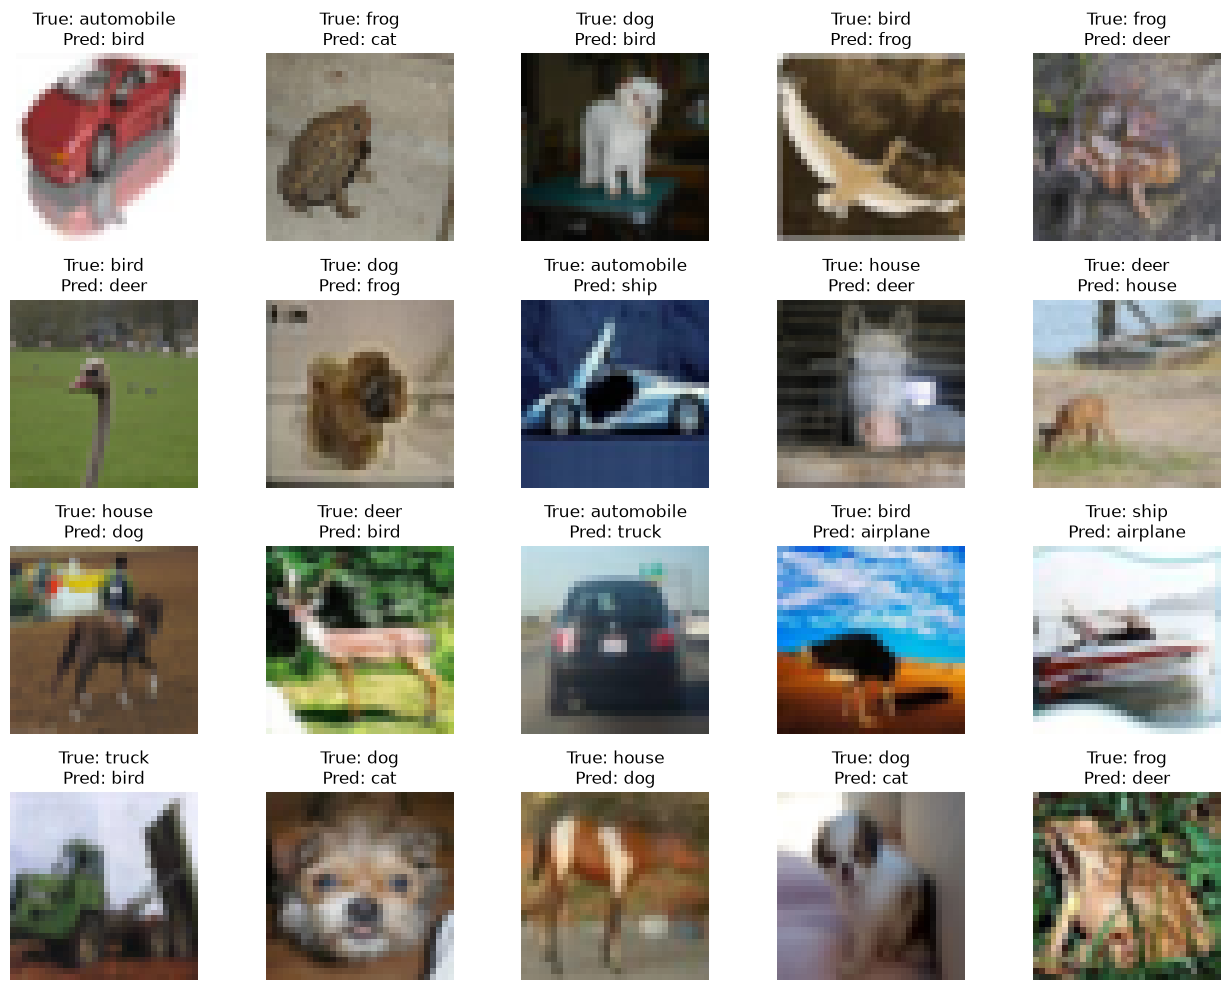

In [64]:
# Display 20 misclassified images for human inspection
wrong_indices = np.where(
    true_labels != predicted_labels
)[0][:20]

fig, ax = plt.subplots(4, 5, figsize=(13, 10))

for i, ax in enumerate(ax.flat):
    if i >= len(wrong_indices):
        ax.axis("off")
        continue

    index = wrong_indices[i]

    ax.imshow(all_images[index].permute(1, 2, 0))

    ax.set_title(
        f"True: {class_name[true_labels[index]]}\n"
        f"Pred: {class_name[predicted_labels[index]]}"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

# **Part E — Push further**

In [66]:
# Experiment 1 – Data augmentation
flip_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

flip_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True, download=False, transform=flip_transform
)


flip_train_set = torch.utils.data.Subset(flip_dataset, train_set.indices)

flip_loader = DataLoader(flip_train_set, batch_size=128, shuffle=True)

flip_model = CNN()

flip_model, flip_history, flip_time = train_model(flip_model, flip_loader, val_loader, epochs=8)

print("Horizontal flip Accuracy:", evaluate(flip_model, val_loader)[1])

Epoch 1/8  | Train Loss: 1.5026  | Train Acc: 0.4572  | Val Loss: 1.2310  | Val Acc: 0.5658
Epoch 2/8  | Train Loss: 1.1481  | Train Acc: 0.5902  | Val Loss: 1.1404  | Val Acc: 0.5848
Epoch 3/8  | Train Loss: 1.0151  | Train Acc: 0.6397  | Val Loss: 0.9517  | Val Acc: 0.6676
Epoch 4/8  | Train Loss: 0.9199  | Train Acc: 0.6740  | Val Loss: 0.8966  | Val Acc: 0.6840
Epoch 5/8  | Train Loss: 0.8462  | Train Acc: 0.7016  | Val Loss: 0.8590  | Val Acc: 0.7070
Epoch 6/8  | Train Loss: 0.7869  | Train Acc: 0.7241  | Val Loss: 0.8140  | Val Acc: 0.7168
Epoch 7/8  | Train Loss: 0.7429  | Train Acc: 0.7380  | Val Loss: 0.7986  | Val Acc: 0.7254
Epoch 8/8  | Train Loss: 0.7206  | Train Acc: 0.7456  | Val Loss: 0.7904  | Val Acc: 0.7266

Training Time: 6.55 minutes
Horizontal flip Accuracy: 0.7266


In [67]:
# Random Crop
crop_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor()
])

crop_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False, transform=crop_transform
)

crop_train_set = torch.utils.data.Subset(
    crop_dataset, train_set.indices
)

crop_loader = DataLoader(
    crop_train_set, batch_size=128, shuffle=True
)

crop_model = CNN()

crop_model, crop_history, crop_time = train_model(crop_model, crop_loader, val_loader, epochs=8)

print("Random Crop Accuracy:", evaluate(crop_model, val_loader)[1])

Epoch 1/8  | Train Loss: 1.7170  | Train Acc: 0.3676  | Val Loss: 1.4040  | Val Acc: 0.4826
Epoch 2/8  | Train Loss: 1.4313  | Train Acc: 0.4800  | Val Loss: 1.3051  | Val Acc: 0.5262
Epoch 3/8  | Train Loss: 1.3211  | Train Acc: 0.5215  | Val Loss: 1.1540  | Val Acc: 0.5902
Epoch 4/8  | Train Loss: 1.2309  | Train Acc: 0.5580  | Val Loss: 1.0683  | Val Acc: 0.6180
Epoch 5/8  | Train Loss: 1.1500  | Train Acc: 0.5881  | Val Loss: 1.0103  | Val Acc: 0.6420
Epoch 6/8  | Train Loss: 1.1045  | Train Acc: 0.6044  | Val Loss: 0.9667  | Val Acc: 0.6554
Epoch 7/8  | Train Loss: 1.0678  | Train Acc: 0.6179  | Val Loss: 0.9468  | Val Acc: 0.6634
Epoch 8/8  | Train Loss: 1.0475  | Train Acc: 0.6257  | Val Loss: 0.9382  | Val Acc: 0.6706

Training Time: 6.41 minutes
Random Crop Accuracy: 0.6706


In [68]:
# Combine both augmentations
combined_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

combined_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=combined_transform
)

combined_train_set = torch.utils.data.Subset(
    combined_dataset,
    train_set.indices
)

combined_loader = DataLoader(
    combined_train_set,
    batch_size=128,
    shuffle=True
)

combined_model = CNN()

combined_model, combined_history, combined_time = train_model(
    combined_model,
    combined_loader,
    val_loader,
    epochs=8
)

print(
    "Combined augmentation accuracy:",
    evaluate(combined_model, val_loader)[1]
)

Epoch 1/8  | Train Loss: 1.6836  | Train Acc: 0.3838  | Val Loss: 1.3905  | Val Acc: 0.5010
Epoch 2/8  | Train Loss: 1.3755  | Train Acc: 0.5029  | Val Loss: 1.1628  | Val Acc: 0.5804
Epoch 3/8  | Train Loss: 1.2316  | Train Acc: 0.5564  | Val Loss: 1.0805  | Val Acc: 0.6210
Epoch 4/8  | Train Loss: 1.1309  | Train Acc: 0.5944  | Val Loss: 0.9988  | Val Acc: 0.6536
Epoch 5/8  | Train Loss: 1.0587  | Train Acc: 0.6225  | Val Loss: 0.9298  | Val Acc: 0.6792
Epoch 6/8  | Train Loss: 1.0161  | Train Acc: 0.6406  | Val Loss: 0.8955  | Val Acc: 0.6872
Epoch 7/8  | Train Loss: 0.9814  | Train Acc: 0.6525  | Val Loss: 0.8621  | Val Acc: 0.6962
Epoch 8/8  | Train Loss: 0.9611  | Train Acc: 0.6599  | Val Loss: 0.8523  | Val Acc: 0.6980

Training Time: 6.52 minutes
Combined augmentation accuracy: 0.698


In [69]:
# Compare augmentation results}

print("Normal CNN:",
      evaluate(cnn_model, val_loader)[1])

print("Horizontal flip:",
      evaluate(flip_model, val_loader)[1])

print("Random crop:",
      evaluate(crop_model, val_loader)[1])

print("Combined:",
      evaluate(combined_model, val_loader)[1])

Normal CNN: 0.7304
Horizontal flip: 0.7266
Random crop: 0.6706
Combined: 0.698


In [70]:
# Experiment 2 – Batch normalization
batch_norm_model = CNN(batch_norm=True)

batch_norm_model, bn_history, bn_time = train_model(
    batch_norm_model,
    train_loader,
    val_loader,
    epochs=8
)

print(
    "Batch normalization accuracy:",
    evaluate(batch_norm_model, val_loader)[1]
)

print(
    "Batch normalization parameters:",
    count_parameters(batch_norm_model)
)

print("Batch normalization training time:", bn_time / 60)

Epoch 1/8  | Train Loss: 1.6422  | Train Acc: 0.4163  | Val Loss: 1.2955  | Val Acc: 0.5340
Epoch 2/8  | Train Loss: 1.2249  | Train Acc: 0.5592  | Val Loss: 1.3049  | Val Acc: 0.5408
Epoch 3/8  | Train Loss: 1.0705  | Train Acc: 0.6195  | Val Loss: 1.1301  | Val Acc: 0.5976
Epoch 4/8  | Train Loss: 0.9721  | Train Acc: 0.6553  | Val Loss: 0.9012  | Val Acc: 0.6780
Epoch 5/8  | Train Loss: 0.8981  | Train Acc: 0.6790  | Val Loss: 0.9615  | Val Acc: 0.6632
Epoch 6/8  | Train Loss: 0.8387  | Train Acc: 0.7022  | Val Loss: 0.8317  | Val Acc: 0.7168
Epoch 7/8  | Train Loss: 0.7833  | Train Acc: 0.7201  | Val Loss: 0.7915  | Val Acc: 0.7254
Epoch 8/8  | Train Loss: 0.7477  | Train Acc: 0.7325  | Val Loss: 0.7616  | Val Acc: 0.7304

Training Time: 7.74 minutes
Batch normalization accuracy: 0.7304
Batch normalization parameters: 2176010
Batch normalization training time: 7.737542287508647


In [71]:
# Experiment 3 – Add a third convolution block
deep_cnn = CNN(extra_block=True)

print(
    "Deep CNN parameters:",
    count_parameters(deep_cnn)
)

deep_cnn, deep_history, deep_time = train_model(
    deep_cnn,
    train_loader,
    val_loader,
    epochs=8
)

print(
    "Deep CNN validation accuracy:",
    evaluate(deep_cnn, val_loader)[1]
)

print("Deep CNN training time:", deep_time / 60)

Deep CNN parameters: 1422218
Epoch 1/8  | Train Loss: 1.5827  | Train Acc: 0.4215  | Val Loss: 1.2840  | Val Acc: 0.5428
Epoch 2/8  | Train Loss: 1.1676  | Train Acc: 0.5826  | Val Loss: 1.1104  | Val Acc: 0.6044
Epoch 3/8  | Train Loss: 0.9690  | Train Acc: 0.6570  | Val Loss: 0.9256  | Val Acc: 0.6812
Epoch 4/8  | Train Loss: 0.8325  | Train Acc: 0.7064  | Val Loss: 0.8661  | Val Acc: 0.7078
Epoch 5/8  | Train Loss: 0.7277  | Train Acc: 0.7450  | Val Loss: 0.7939  | Val Acc: 0.7266
Epoch 6/8  | Train Loss: 0.6413  | Train Acc: 0.7773  | Val Loss: 0.7568  | Val Acc: 0.7460
Epoch 7/8  | Train Loss: 0.5761  | Train Acc: 0.8005  | Val Loss: 0.7364  | Val Acc: 0.7526
Epoch 8/8  | Train Loss: 0.5372  | Train Acc: 0.8134  | Val Loss: 0.7286  | Val Acc: 0.7568

Training Time: 7.74 minutes
Deep CNN validation accuracy: 0.7568
Deep CNN training time: 7.737403384844462


In [73]:
# Experiment 4 – Black, white and random noise images
def predict_image(model, image, image_name):

    model.eval()

    with torch.no_grad():

        image = image.to(device)

        outputs = model(image)

        probabilities = torch.softmax(outputs, dim=1)

        confidence, prediction = probabilities.max(dim=1)

    print("\nImage:", image_name)

    print(
        "Prediction:",
        class_name[prediction.item()]
    )

    print(
        "Confidence:",
        round(confidence.item() * 100, 2),
        "%"
    )


black_image = torch.zeros(1, 3, 32, 32)

white_image = torch.ones(1, 3, 32, 32)

random_image = torch.rand(1, 3, 32, 32)


predict_image(cnn_model, black_image, "Black Image")

predict_image(cnn_model, white_image, "White Image")

predict_image(cnn_model, random_image, "Random Noise")


Image: Black Image
Prediction: cat
Confidence: 99.19 %

Image: White Image
Prediction: airplane
Confidence: 34.43 %

Image: Random Noise
Prediction: truck
Confidence: 95.01 %


In [74]:
# Experiment 5 – 1×1 convolution
class OneByOneCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),

            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),

            nn.Linear(256, 10)
        )

    def forward(self, x):

        return self.network(x)


one_by_one_model = OneByOneCNN()

print(
    "1x1 CNN parameters:",
    count_parameters(one_by_one_model)
)

one_by_one_model, one_by_one_history, one_by_one_time = train_model(
    one_by_one_model,
    train_loader,
    val_loader,
    epochs=8
)

print(
    "1x1 CNN validation accuracy:",
    evaluate(one_by_one_model, val_loader)[1]
)

1x1 CNN parameters: 2176842
Epoch 1/8  | Train Loss: 1.5790  | Train Acc: 0.4300  | Val Loss: 1.3373  | Val Acc: 0.5318
Epoch 2/8  | Train Loss: 1.1896  | Train Acc: 0.5740  | Val Loss: 1.1449  | Val Acc: 0.5980
Epoch 3/8  | Train Loss: 1.0269  | Train Acc: 0.6342  | Val Loss: 1.0505  | Val Acc: 0.6316
Epoch 4/8  | Train Loss: 0.9099  | Train Acc: 0.6782  | Val Loss: 0.9718  | Val Acc: 0.6594
Epoch 5/8  | Train Loss: 0.8091  | Train Acc: 0.7166  | Val Loss: 0.9959  | Val Acc: 0.6570
Epoch 6/8  | Train Loss: 0.7343  | Train Acc: 0.7438  | Val Loss: 0.9094  | Val Acc: 0.6926
Epoch 7/8  | Train Loss: 0.6702  | Train Acc: 0.7682  | Val Loss: 0.8926  | Val Acc: 0.7012
Epoch 8/8  | Train Loss: 0.6357  | Train Acc: 0.7813  | Val Loss: 0.8883  | Val Acc: 0.7002

Training Time: 4.89 minutes
1x1 CNN validation accuracy: 0.7002


# **Final evaluation – CIFAR-10 test accuracy**

In [75]:
test_loss, test_accuracy = evaluate(
    cnn_model,
    test_loader
)

print("\n========== FINAL TEST RESULTS ==========")

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

print("Test Accuracy Percentage:", test_accuracy * 100)

print("CNN Parameters:", count_parameters(cnn_model))

print("Dense Parameters:", count_parameters(dense_model))

print("CNN Training Time:", cnn_time / 60, "minutes")

print("Dense Training Time:", dense_time / 60, "minutes")


========== FINAL TEST RESULTS ==========
Test Loss: 0.9711339068412781
Test Accuracy: 0.7308
Test Accuracy Percentage: 73.08
CNN Parameters: 2175626
Dense Parameters: 1707274
CNN Training Time: 22.640207119782765 minutes
Dense Training Time: 0.9017558773358663 minutes


# **Final results comparison**

In [78]:
results = {
    "Dense Baseline": dense_accuracy,
    "CNN": cnn_accuracy if "cnn_accuracy" in globals() else evaluate(cnn_model, val_loader)[1],
    "CNN without pooling": no_pool_accuracy,
    "CNN average pooling": avg_accuracy,
    "CNN shuffled": cnn_shuffled_accuracy,
    "Dense shuffled": dense_shuffled_accuracy,
    "CNN with batch norm": evaluate(batch_norm_model, val_loader)[1],
    "CNN with augmentation": evaluate(combined_model, val_loader)[1],
    "Deep CNN": evaluate(deep_cnn, val_loader)[1]
}

print("\nFINAL VALIDATION COMPARISON")

for name, accuracy in results.items():

    print(f"{name}: {accuracy:.4f}")


FINAL VALIDATION COMPARISON
Dense Baseline: 0.4864
CNN: 0.7304
CNN without pooling: 0.6626
CNN average pooling: 0.6702
CNN shuffled: 0.5020
Dense shuffled: 0.4852
CNN with batch norm: 0.7304
CNN with augmentation: 0.6980
Deep CNN: 0.7568
